# STATS 201 Week 4 · Causal machine learning

**What would change if we intervened?** For one restaurant or factory workcell, we observe the result under the action it received. The result under another action is its **counterfactual** (反事实). **Identification** (识别) means justifying a comparison for that missing result. **Estimation** (估计) means calculating the size of the difference.

[Open this lab in Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/04-causal-inference/week04_causal_ml.ipynb). Read your route’s question and variable table first. Then choose **Runtime → Run all**. Save a copy in Drive before editing the settings.

| Route | Question | One change to try |
| --- | --- | --- |
| A · Economist | How did a minimum-wage increase affect restaurant staffing? | In the separate A5 simulation, set `TREND_BIAS = 1.5`. |
| B · Computer scientist | How would a different robot assistance level change a factory workcell’s inspection score? | Set `TIMING = "ordered"`. Compare B2’s graphs and B3’s estimates. |

A1–A4 use a historical survey. A5 simulates adoption over time. B1–B4 simulate different assistance levels at one snapshot per workcell.


In [1]:
from itertools import combinations, product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Edit one setting, then use Runtime → Run all.
SEED = 201
TRUE_EFFECT = 3.0
TREND_BIAS = 0.0       # A5 changes this to 1.5.
TIMING = "baseline"    # B2 compares this with "ordered".
HIDDEN_STRENGTH = 0.0  # Optional B4 check of an omitted scheduling factor.
RUN_SURVEY_CASE = True
SURVEY_CSV_PATH = ""   # Optional local copy of the pinned survey CSV.

if TIMING not in {"baseline", "ordered"}:
    raise ValueError('Choose TIMING = "baseline" or "ordered".')

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
})


# A · Economist route

## A1 · Question, treatment, and economic hypothesis

**Guiding question.** What happened to fast-food staffing after New Jersey raised its minimum wage, relative to the staffing change we would expect without the increase?

The [2021 Prize in Economic Sciences](https://www.nobelprize.org/uploads/2021/10/press-economicsciencesprize2021-2.pdf) recognized David Card's empirical contributions to labor economics and Joshua Angrist and Guido Imbens's work on causal relationships. [Card and Krueger (1994)](https://eml.berkeley.edu/~card/papers/njmin-aer.pdf) compared fast-food restaurants in New Jersey and eastern Pennsylvania. On April 1, 1992, the minimum wage rose from **$4.25 to $5.05 per hour** in New Jersey and stayed **$4.25** in Pennsylvania.

| Design element | Definition in this case |
| --- | --- |
| Unit | A sampled restaurant from one of four chains, observed in two survey waves |
| Treatment | Exposure to the New Jersey minimum-wage increase after April 1. Actual pay and compliance can vary. |
| Outcome | Full-time-equivalent (FTE) employment per restaurant, counting full-time workers including managers plus half of part-time workers |
| Target effect | Mean FTE with the policy minus mean FTE under the no-increase counterfactual at follow-up for exposed New Jersey restaurants |
| Comparison and controls | Pennsylvania supplies the comparison trend. Differencing accounts for time-invariant restaurant characteristics and a common period shift. We also check sensitivity to pre-policy chain and company ownership. |
| Variables measured after treatment | Follow-up wage and hours may respond to the policy. Keep them out of the main adjustment for the total policy effect. |

**Why could employment change?** A binding wage floor changes the cost or availability of labor. Under competitive labor demand, a higher wage can reduce staffing when other inputs and product demand are fixed. With employer wage-setting power and upward-sloping labor supply, a moderate floor can reduce the gap between wages and marginal hiring cost and may increase hiring. Restaurants can also adjust hours, prices, or staffing composition. These mechanisms motivate the two-sided hypothesis $H_0:\tau_{\mathrm{ATT}}=0$ versus $H_1:\tau_{\mathrm{ATT}}\ne0$. The sign and magnitude remain empirical questions.

### Two 2026 readings

1. [Baker, Callaway, Cunningham, Goodman-Bacon & Sant'Anna, *Difference-in-Differences Designs: A Practitioner's Guide*](https://doi.org/10.1257/jel.20251650). Use the guide to examine who was exposed, which groups supply a comparison trend, and when a pretreatment check is possible.
2. [Wiltshire, McPherson, Reich & Sosinskiy, *Minimum Wage Effects and Monopsony Explanations*](https://doi.org/10.1086/735551). Use its analysis of minimum wages and employer market power to ask what data would distinguish mechanisms. The classroom analysis estimates a policy contrast. A mechanism test would need additional evidence.

## A2 · Source data and outcome construction

**Guiding question.** What enters the estimate and which restaurants are lost when we require two observed outcomes?

The [authors' public survey archive](https://davidcard.berkeley.edu/data_sets/njmin.zip) covers 410 restaurants (331 New Jersey, 79 eastern Pennsylvania). Wave 1 was in February–March 1992. Wave 2 began in November, with follow-up into December. Each source row contains before and after fields. The code tries the authors' public.dat first and can load a [pinned raw-field CSV copy](https://github.com/isaG001/card-krueger-replication/blob/cd9f1a0f7b04ae5386d7da1c89f5bd31116e430e/card_krueger_1994.csv) if needed. The saved run uses that pinned copy. FTE is recomputed from the component fields, and missing components remain missing.

| Source fields | How they enter |
| --- | --- |
| `state`, `chain`, `co_owned` | New Jersey indicator, chain, and whether the outlet is company-owned |
| `empft`, `nmgrs`, `emppt` and corresponding `…2` fields | Full-time, manager and part-time worker counts for wave 1 and wave 2 |
| `wage_st`, `wage_st2` | Starting wage in dollars per hour. Its change is context for policy exposure. |
| `status2` | Follow-up status. Examine closure and nonresponse when appraising the paired sample. |

Use two observed outcomes per restaurant for the main contrast, preserving recorded zero employment. The code never imputes a missing employment component as zero. Some paper tables use a different missingness and closure rule.

In [2]:
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import BadZipFile, ZipFile

CK_ARCHIVE = "https://davidcard.berkeley.edu/data_sets/njmin.zip"
CK_CSV = ("https://raw.githubusercontent.com/isaG001/card-krueger-replication/"
          "cd9f1a0f7b04ae5386d7da1c89f5bd31116e430e/card_krueger_1994.csv")
CK_CSV_SHA256 = "bfd49ba946a3d6ff7afbdda10a5239b8f345278837ef574067d8ad545652022e"
SURVEY_FIELDS = """
sheet chain co_owned state southj centralj northj pa1 pa2 shore ncalls
empft emppt nmgrs wage_st inctime firstinc bonus pctaff meals open hrsopen
psoda pfry pentree nregs nregs11 type2 status2 date2 ncalls2 empft2 emppt2
nmgrs2 wage_st2 inctime2 firstin2 special2 meals2 open2r hrsopen2 psoda2
pfry2 pentree2 nregs2 nregs112
""".split()


def pinned_csv(raw):
    if sha256(raw).hexdigest() != CK_CSV_SHA256:
        raise ValueError("The pinned survey CSV has a different checksum.")
    return pd.read_csv(BytesIO(raw))


def read_survey():
    if SURVEY_CSV_PATH:
        return pinned_csv(Path(SURVEY_CSV_PATH).read_bytes()), "Pinned survey CSV (local copy)"
    try:
        with urlopen(CK_ARCHIVE, timeout=12) as response, ZipFile(BytesIO(response.read())) as archive:
            name = next(path for path in archive.namelist() if Path(path).name.lower() == "public.dat")
            data = pd.read_csv(archive.open(name), sep=r"\s+", names=SURVEY_FIELDS, na_values=".")
        return data, "Card’s public.dat archive"
    except (OSError, BadZipFile, StopIteration, ValueError):
        print("Trying the pinned survey CSV.")
    try:
        with urlopen(CK_CSV, timeout=12) as response:
            return pinned_csv(response.read()), "Pinned survey CSV"
    except (OSError, ValueError):
        print("Survey unavailable. Use the saved survey results and continue to the simulations.")
        return None, None


def make_fte(data, part_weight=0.5):
    before = data.empft + data.nmgrs + part_weight * data.emppt
    after = data.empft2 + data.nmgrs2 + part_weight * data.emppt2
    return data.assign(before=before, after=after, change=after - before)


survey, source = read_survey() if RUN_SURVEY_CASE else (None, None)
if survey is not None:
    assert survey.state.value_counts().to_dict() == {1: 331, 0: 79}
    survey = make_fte(survey)
    print(f"Data source: {source}")
    coverage = survey.groupby("state").agg(
        restaurants=("state", "size"), before_observed=("before", "count"),
        after_observed=("after", "count"), paired=("change", "count"),
        starting_wage_before=("wage_st", "mean"), starting_wage_after=("wage_st2", "mean"),
    ).rename(index={0: "PA", 1: "NJ"})
    print(coverage.round(2).to_string())


Data source: Pinned survey CSV (local copy)
       restaurants  before_observed  after_observed  paired  starting_wage_before  starting_wage_after
state                                                                                                 
PA              79               77              77      75                  4.63                 4.62
NJ             331              321             319     309                  4.61                 5.08


## A3 · Identify and estimate the policy effect

**Guiding question.** When can Pennsylvania's change stand in for New Jersey's missing counterfactual?

Write $Y_{i1}(1)$ and $Y_{i1}(0)$ for the follow-up outcome with and without the increase. The target is $\tau_{\mathrm{ATT}}=E[Y_{i1}(1)-Y_{i1}(0)\mid G_i=1]$, where $G_i=1$ marks New Jersey. With no anticipation and **parallel untreated trends**, the groups would share the same mean change without the policy:

$$E[Y_{i1}(0)-Y_{i0}(0)\mid G_i=1]=E[Y_{i1}(0)-Y_{i0}(0)\mid G_i=0].$$

$$\widehat{\tau}_{\rm DiD}=(\bar Y_{\rm NJ,post}-\bar Y_{\rm NJ,pre})
 -(\bar Y_{\rm PA,post}-\bar Y_{\rm PA,pre}).$$

In a two-period regression on New Jersey, post, and their interaction, the interaction is the DiD for the same paired sample. For the adjusted sensitivity, regress the change on New Jersey, chain and company ownership, $\Delta Y_i=\alpha+\tau G_i+\gamma^\top X_i+e_i$. A causal interpretation requires credible parallel trends given those covariates, overlap, and a suitable model. Also consider spillovers, differential survey response, and other events that could have affected one state's staffing.

**Pseudocode**

1. Recode both outcomes in FTE. Keep restaurants with both observed.
2. Average the store-level changes separately by state.
3. Subtract the Pennsylvania change from the New Jersey change.
4. Add the Pennsylvania change to New Jersey's baseline to draw its implied no-policy trajectory. Recompute under alternative definitions and sample restrictions.

**Python.** `pandas` reads and groups the data, `scikit-learn` fits the adjustment sensitivity, and `Matplotlib` draws the comparison. `SciPy` computes the interval in the synthetic panel below. [statsmodels](https://www.statsmodels.org/stable/) and [PyFixest](https://pyfixest.org/) support regression and richer DiD workflows for designs with suitable independent assignment units.

       before  after  change
state                       
PA      23.38   21.1   -2.28
NJ      20.43   20.9    0.47

DiD: +2.75 FTE per restaurant. Implied NJ without the policy: 18.15 FTE.
Contrast as a share of NJ’s starting FTE: 13.5%


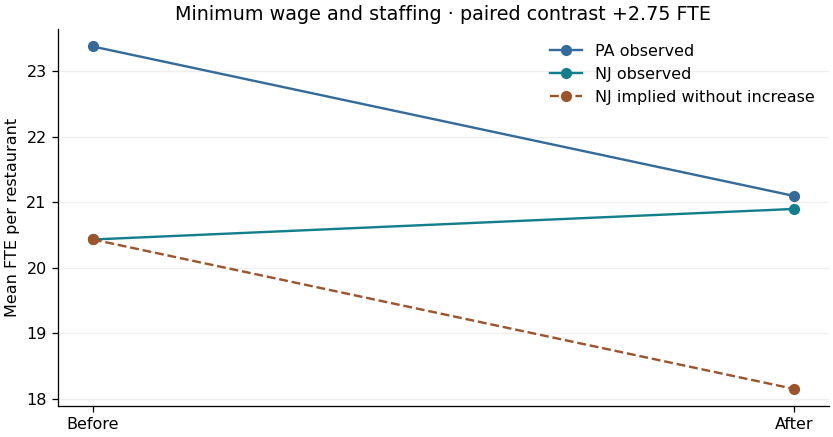

In [3]:
def paired_contrast(data):
    pairs = data.dropna(subset=["change"])
    means = pairs.groupby("state")[["before", "after", "change"]].mean()
    return means.loc[1, "change"] - means.loc[0, "change"], means, pairs


if survey is not None:
    ck_did, ck_means, ck_pairs = paired_contrast(survey)
    nj_pre = ck_means.loc[1, "before"]
    nj_counterfactual = nj_pre + ck_means.loc[0, "change"]
    print(ck_means.rename(index={0: "PA", 1: "NJ"}).round(2).to_string())
    print(f"\nDiD: {ck_did:+.2f} FTE per restaurant. Implied NJ without the policy: {nj_counterfactual:.2f} FTE.")
    print(f"Contrast as a share of NJ’s starting FTE: {ck_did / nj_pre:.1%}")

    fig, ax = plt.subplots(figsize=(7.25, 3.8), layout="constrained")
    trends = ck_means[["before", "after"]].rename(index={0: "PA observed", 1: "NJ observed"}).T
    trends.plot(ax=ax, marker="o", color=["#356B99", "#137F8C"])
    ax.plot([0, 1], [nj_pre, nj_counterfactual], "--o", color="#9D542B", label="NJ implied without increase")
    ax.set(xticks=[0, 1], xticklabels=["Before", "After"], ylabel="Mean FTE per restaurant",
           title=f"Minimum wage and staffing · paired contrast {ck_did:+.2f} FTE")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=.2)
    plt.show()


## A4 · Interpret the plot and check robustness

**Guiding question.** Does the contrast reflect staffing growth in New Jersey, a fall in Pennsylvania, or both?

Read the two observed lines. The dashed line starts at New Jersey's observed baseline and applies Pennsylvania's observed change. The vertical gap to New Jersey's follow-up is the estimated DiD. Report the four means, both changes, the contrast and the paired sample sizes. In the saved run, New Jersey gains 0.47 FTE and Pennsylvania loses 2.28. Their difference is +2.75 FTE per restaurant, matching the paired contrast in Table 3. Most of the contrast comes from Pennsylvania's decline. Relative to New Jersey's 20.43 baseline FTE, the scale is about 13.5%. This is a baseline-scaled comparison, while observed staffing growth in New Jersey is 0.47 FTE.

**Statistical uncertainty.** Exposure varied at the state level, with one treated and one comparison state. Hundreds of stores do not create hundreds of independent policy assignments. Therefore, this class analysis reports the observed contrast and sensitivity estimates. The simulation below demonstrates how to interpret an interval when the workcells are independent by construction.

**Check sensitivity.** Recompute using all available wave means, change the part-time weight, remove one chain at a time, and condition on pre-policy chain and company ownership. These checks probe different sample and measurement decisions.

In [4]:
if survey is not None:
    available = survey.groupby("state")[["before", "after"]].mean()
    change = available.after - available.before
    checks = {
        "Paired sample": ck_did,
        "All observed outcomes in each wave": change.loc[1] - change.loc[0],
    }
    for weight in (0.25, 0.75):
        checks[f"Part-time weight {weight}"] = paired_contrast(make_fte(survey, weight))[0]

    chains = {1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy’s"}
    for code, name in chains.items():
        checks[f"Leave out {name}"] = paired_contrast(survey[survey.chain != code])[0]

    baseline = ck_pairs[["state", "chain", "co_owned"]].astype({"chain": "category"})
    controls = pd.get_dummies(baseline, columns=["chain"], drop_first=True)
    model = LinearRegression().fit(controls, ck_pairs.change)
    checks["Adjust for baseline chain and ownership"] = model.coef_[0]
    print(pd.Series(checks, name="Contrast (FTE)").round(2).to_string())


Paired sample                              2.75
All observed outcomes in each wave         2.75
Part-time weight 0.25                      2.92
Part-time weight 0.75                      2.58
Leave out Burger King                      1.55
Leave out KFC                              3.56
Leave out Roy Rogers                       2.90
Leave out Wendy’s                          2.64
Adjust for baseline chain and ownership    2.78


The saved estimates range from +1.55 FTE after leaving out Burger King to +3.56 after leaving out KFC. Conditioning on chain and company ownership gives +2.78. The direction persists across these checks, while the magnitude is sensitive to the chain mix. A shared unobserved change could still bias every estimate.

**What could improve the real study?** With one pre-policy wave we cannot check a pretrend. Several earlier periods, more comparison jurisdictions and policy dates, and administrative payroll and hours records would strengthen the comparison. Check business closures, response rates, and whether staffing or consumers moved across the state border. To distinguish monopsony from other explanations, seek independent evidence on workers' outside options, recruiting, and employer wage-setting.

**Apply the check.** Name one covariate recorded before the policy and one post-policy outcome you would avoid adjusting for. What extra evidence could make Pennsylvania a more or less credible comparison?


## A5 · Run the economist team's stress test

**Guiding question.** What happens to a precise estimate when the comparison trend is wrong?

Use a separate **simulation** of 200 workcells. A row has one score at each of four periods, −2, −1, 0 and 1. Adoption starts at period 0 for group $G_i=1$. Given independent standard normal $X_i,a_i,\eta_i,\epsilon_{it}$, the simulator uses $G_i=1[0.8X_i+\eta_i>0]$, a fixed baseline $B_i=70+3X_i+2G_i+2a_i$, and

$$Y_{it}=B_i+1.2t+\delta G_i t+\tau G_i1[t\geq0]+\epsilon_{it}.$$

$\tau=3$ by default and $\delta$ is `TREND_BIAS`. At $\delta=0$, untreated trends are parallel. A nonzero $\delta$ assigns adopters a different underlying trend. The code calculates one before-to-after change per workcell and builds a **Welch 95% interval** for the difference in mean changes. The pre-period contrast (−2 to −1) checks for a difference before adoption. In real designs, uncertainty needs to reflect the assignment unit.


Each row is a workcell. Columns −2 through 1 are its scores by period.
   -2    -1     0     1  adopter
73.91 77.34 80.28 80.28        1
66.41 70.03 70.93 72.69        1
63.25 65.57 69.08 69.65        1
65.59 66.61 70.98 71.91        1
71.86 72.77 77.32 78.01        1

Adoption contrast: 2.78 points, 95% interval [2.39, 3.17]
Pre-adoption placebo: 0.29, interval [-0.10, 0.67]
Known simulated adoption effect: 3.00 points


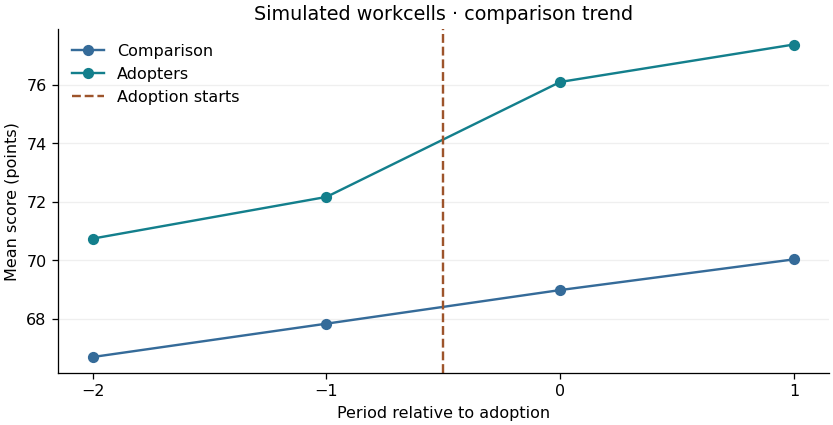

In [5]:
rng = np.random.default_rng(SEED)
n_cells = 200
mix, baseline_noise, adoption_noise = rng.standard_normal((3, n_cells))
adopter = (0.8 * mix + adoption_noise > 0).astype(int)
baseline = 70 + 3 * mix + 2 * adopter + 2 * baseline_noise
periods = np.array([-2, -1, 0, 1])
noise = rng.standard_normal((n_cells, len(periods)))
scores = (baseline[:, None] + 1.2 * periods + TREND_BIAS * adopter[:, None] * periods
          + TRUE_EFFECT * adopter[:, None] * (periods >= 0) + noise)
panel = pd.DataFrame(scores, columns=periods).assign(adopter=adopter)
print("Each row is a workcell. Columns −2 through 1 are its scores by period.")
print(panel.head().round(2).to_string(index=False))


def change_contrast(before, after):
    changes = panel[after] - panel[before]
    treated, comparison = changes[panel.adopter == 1], changes[panel.adopter == 0]
    interval = stats.ttest_ind(treated, comparison, equal_var=False).confidence_interval()
    return treated.mean() - comparison.mean(), interval.low, interval.high


did = change_contrast(-1, 0)
placebo = change_contrast(-2, -1)
print(f"\nAdoption contrast: {did[0]:.2f} points, 95% interval [{did[1]:.2f}, {did[2]:.2f}]")
print(f"Pre-adoption placebo: {placebo[0]:.2f}, interval [{placebo[1]:.2f}, {placebo[2]:.2f}]")
print(f"Known simulated adoption effect: {TRUE_EFFECT:.2f} points")

means = panel.groupby("adopter")[list(periods)].mean().T
means = means.rename(columns={0: "Comparison", 1: "Adopters"})
fig, ax = plt.subplots(figsize=(7.25, 3.7), layout="constrained")
for group, color in [("Comparison", "#356B99"), ("Adopters", "#137F8C")]:
    ax.plot(periods, means[group], marker="o", color=color, label=group)
ax.axvline(-0.5, linestyle="--", color="#9D542B", label="Adoption starts")
ax.set(xticks=periods, xlabel="Period relative to adoption", ylabel="Mean score (points)",
       title="Simulated workcells · comparison trend")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
plt.show()


**Economist report.** Change `TREND_BIAS` from 0.0 to 1.5 and rerun. Record the default and rerun estimates, new interval and placebo. Explain the change in the estimate given the simulator's known effect. A near-zero placebo can miss a later differential shock. Relate one of the checks to the historical case and name the extra field data you would seek.

# B · Computer scientist route

## B1 · What is the factory deciding?

Imagine a workcell where a robot positions metal parts for a camera to inspect for scratches. The factory is deciding whether to increase robot assistance. **For the same workcell, how many inspection-score points would change if we moved assistance from 0 to 1?** The scratch-inspection example is a way to picture the task. The numbers come from a simulation.

| Variable | What it means | Role in the graph |
| --- | --- | --- |
| $X$ · Product mix 产品组合 | A standardized number describing which parts the workcell handles. It is recorded first. | **Common cause.** Product mix can affect both the assistance assigned and the score. |
| $T$ · Robot assistance 辅助强度 | A standardized assistance level. $0$ is the reference setting and $1$ is one unit higher. | **Treatment.** This is what we change in the causal question. |
| $Y$ · Inspection score 质检评分 | The workcell's inspection performance, measured in points. | **Outcome.** This is what we check for a change. |
| $U$ · Scheduling 排班 | A second common cause in the B4 exercise. The simulator knows it. The starting analysis uses the recorded columns $X,T,Y$. | **Possible omitted cause.** In B4, it affects both $T$ and $Y$. |

**The effect we want.** Let $Y_i(0)$ and $Y_i(1)$ be the scores that the *same* workcell $i$ would have under the two settings. We observe its score at the setting it received. Average the two-setting gap:

$$\tau=\mathbb{E}[Y(1)-Y(0)].$$

Here $\mathbb{E}$ means average. The unit is **score points for a change from assistance 0 to 1**.

**中文要点。** 同一个工位，产品组合相同，把辅助从 0 调到 1，质检评分会变多少？


### How did we create the data?

In the default simulation, draw a product mix $X$ and two independent random terms, $\varepsilon_T$ and $\varepsilon_Y$, for each of 1,800 workcells. All three are standard normal draws, centered at zero with standard deviation one. Each row records one workcell at one snapshot.

$$
T=\frac{0.7X+\varepsilon_T}{\sqrt{1.49}},\qquad
Y=70+3T+1.8X+2\varepsilon_Y.
$$

Read the first equation as **mix plus other assignment variation produces the assistance level**. The denominator sets that level to a unit-standard-deviation scale. Read the second as **a starting score of 70, plus the contributions of assistance, mix and random score variation**. The coefficient on $T$ is set to $3$ in the starting settings.

The graph shows those dependencies. **$X\to T$** means the products affect the assistance assigned. **$X\to Y$** means the products also affect the score. **$T\to Y$** is the effect we built into this simulation.

**Work it out once by hand.** Take one workcell with $X=1$ and $\varepsilon_Y=0$. Set $T=0$ and the score is $71.8$. Set $T=1$ for that same workcell and the score is $74.8$. The gap is $3.0$ points. Since the same $3T$ term operates for every row, the simulator’s known average effect is **+3.00 points**.

The generator uses the same random seed for each rerun. B2 uses the three observed columns to see what an analyst could infer from the records.


First five recorded workcells · X = product mix, T = assistance, Y = score
    X     T     Y
 1.81  1.01 78.02
-0.73  0.07 68.70
-1.09 -0.97 66.40
-0.40 -0.36 65.10
-1.15  0.03 68.05


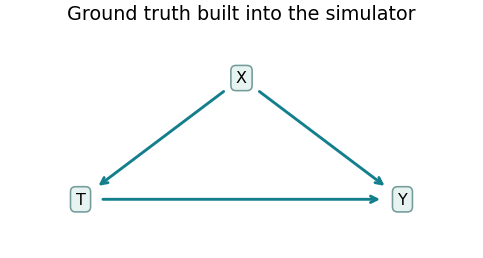

In [6]:
def simulate_workcells(hidden_strength=0.0):
    rng = np.random.default_rng(SEED + 1)
    mix, schedule, dose_noise, score_noise = rng.standard_normal((4, 1_800))
    h = hidden_strength
    dose = (0.7 * mix + h * schedule + dose_noise) / np.sqrt(1.49 + h**2)
    score = 70 + TRUE_EFFECT * dose + 1.8 * mix + 2 * h * schedule + 2 * score_noise
    return pd.DataFrame({"X": mix, "T": dose, "Y": score, "U": schedule})


def draw_graph(ax, arrows, title):
    positions = {"X": (0.5, 0.78), "T": (0.16, 0.24), "Y": (0.84, 0.24)}
    if any("U" in edge for edge in arrows):
        positions.update({"X": (0.24, 0.78), "U": (0.76, 0.78)})
    for start, end in sorted(arrows):
        ax.annotate("", xy=positions[end], xytext=positions[start],
                    arrowprops={"arrowstyle": "->", "color": "#137F8C", "lw": 1.8,
                                "shrinkA": 14, "shrinkB": 14})
    for name, (x, y) in positions.items():
        ax.text(x, y, name, ha="center", va="center",
                bbox={"boxstyle": "round,pad=.32", "fc": "#E7F3F1", "ec": "#749C9B"})
    ax.set(xlim=(0, 1), ylim=(0, 1), title=title)
    ax.axis("off")


obs = simulate_workcells(HIDDEN_STRENGTH)[["X", "T", "Y"]]
truth_graph = {("X", "T"), ("X", "Y")}
if TRUE_EFFECT:
    truth_graph.add(("T", "Y"))
if HIDDEN_STRENGTH:
    truth_graph.update({("U", "T"), ("U", "Y")})
print("First five recorded workcells · X = product mix, T = assistance, Y = score")
print(obs.head().round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(4.2, 2.25), layout="constrained")
draw_graph(ax, truth_graph, "Ground truth built into the simulator")
plt.show()


## B2 · Identification · What would make the comparison credible?

**1. Start with the records.** At first we know that product mix $X$ comes first. Dose $T$ and score $Y$ move together. Which came first? In the default run, the observed relationships fit both diagrams below.

| Candidate | Story | What it implies for the effect |
| --- | --- | --- |
| $X\to T$, $X\to Y$, $T\to Y$ | The factory sets assistance and then scores the inspection. | Changing assistance can change the score. Product mix enters both decisions. |
| $X\to T$, $X\to Y$, $Y\to T$ | The factory uses an already recorded score to help select an assistance setting. | In this graph, changing that setting has a zero effect on that recorded score. |

**2. Add a timing record.** Suppose the dose was set at 09:00 and this score was logged after the inspection at 09:05. Set `TIMING = "ordered"` to supply that order. In the default exercise, the search now keeps $T\to Y$.

**3. Handle the shared cause.** The path $T\leftarrow X\to Y$ is why the raw dose–score comparison can mix assistance effects with product differences. Compare assistance levels among workcells with the same product mix, then average across product mixes:

$$
\mathbb{E}[Y\mid \operatorname{do}(T=t)]
=\mathbb{E}_X\!\left[\mathbb{E}[Y\mid T=t,X]\right].
$$

$\operatorname{do}(T=t)$ means **set assistance to $t$**. The right side means **learn the average score at $t$ for each mix, then average over mixes**. This identifies the effect for the forward graph if $X$ covers the common causes, comparable workcells have support near both settings, and the recorded setting represents the intervention we mean.

**How Python screens the graph.** Use a correlation for each pair, then a **partial correlation**, which measures how the pair moves together after accounting for the third variable. A small $p$-value makes zero correlation less plausible under the test model. With Gaussian variables, zero partial correlation corresponds to conditional independence. The default run finds relationships in all six tests, so all three links remain. The two complete diagrams predict the same pattern of relationships, which is why we need the timing information. The small search also handles data settings that suggest a missing link.

<details>
<summary>Test formulas and pseudocode</summary>

With $A,B$ as a pair and $C$ as the third variable, the correlations $r$ give

$$r_{AB\mid C}
=\frac{r_{AB}-r_{AC}r_{BC}}{\sqrt{(1-r_{AC}^{2})(1-r_{BC}^{2})}}.$$

To test $r=0$, calculate $s=r\sqrt{(n-2-k)/(1-r^2)}$, where $n$ is the number of workcells and $k$ is 0 with no control or 1 when accounting for the third variable. Use a two-sided $t$ test and a cutoff of 0.01.

1. Compare each pair with and without accounting for the third variable.
2. Try three-node graphs with $X$ first. Apply the dose-before-score rule if supplied.
3. Keep graph patterns that match the six tests. Report the compatible directions.
4. For a graph with $T\to Y$, check the assumptions for comparing at the same $X$.

</details>

**中文要点。** 时间日志提供先后顺序。比较相似产品组合的工位，是为了处理产品组合这个共同原因。


First Second Given Correlation        p
    X      T  None       +0.57 8.3e-153
    X      T     Y       -0.16  5.2e-12
    X      Y  None       +0.74  <1e-300
    X      Y     T       +0.59   1e-170
    T      Y  None       +0.84  <1e-300
    T      Y     X       +0.77  <1e-300

Timing: baseline · Compatible graphs: 2


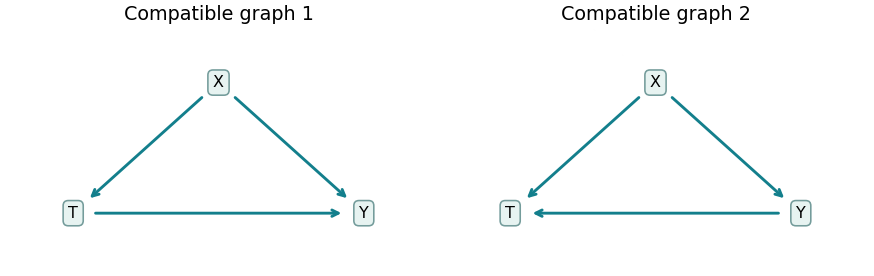

In [7]:
names = ("X", "T", "Y")


def link_tests(data):
    correlations = data[list(names)].corr()
    results = []
    for a, b in combinations(names, 2):
        c = next(name for name in names if name not in (a, b))
        r_ab, r_ac, r_bc = correlations.loc[a, b], correlations.loc[a, c], correlations.loc[b, c]
        partial = (r_ab - r_ac * r_bc) / np.sqrt((1 - r_ac**2) * (1 - r_bc**2))
        for given, r in [(None, r_ab), (c, partial)]:
            df = len(data) - 2 - int(given is not None)
            statistic = r * np.sqrt(df / max(1 - r**2, np.finfo(float).eps))
            results.append((a, b, given, r, 2 * stats.t.sf(abs(statistic), df)))
    return results


def implies_independence(graph, a, b, given):
    if (a, b) in graph or (b, a) in graph:
        return False
    if len(graph) < 2:
        return True
    middle = next(name for name in names if name not in (a, b))
    # With no direct link, the only possible path goes through the third variable.
    into_middle = (a, middle) in graph and (b, middle) in graph
    return given is None if into_middle else given == middle


def compatible_graphs(tests, timing, alpha=0.01):
    choices = [(None, ("X", "T")), (None, ("X", "Y")), (None, ("T", "Y"))]
    if timing == "baseline":
        choices[2] += (("Y", "T"),)
    candidates = [set(edge for edge in option if edge) for option in product(*choices)]
    return [g for g in candidates if all(
        implies_independence(g, a, b, given) == (p >= alpha)
        for a, b, given, _, p in tests
    )]


tests = link_tests(obs)
graphs = compatible_graphs(tests, TIMING)
table = pd.DataFrame(tests, columns=["First", "Second", "Given", "Correlation", "p"])
print(table.to_string(index=False, formatters={
    "Correlation": "{:+.2f}".format, "p": lambda p: "<1e-300" if p < 1e-300 else f"{p:.2g}",
}))
print(f"\nTiming: {TIMING} · Compatible graphs: {len(graphs)}")
if HIDDEN_STRENGTH:
    print("This screen uses the recorded variables. The simulator also has an omitted common cause U.")
if graphs:
    shown = graphs[:2]
    fig, axes = plt.subplots(1, len(shown), figsize=(3.8 * len(shown), 2.4),
                             squeeze=False, layout="constrained")
    for i, (ax, graph) in enumerate(zip(axes[0], shown), start=1):
        draw_graph(ax, graph, f"Compatible graph {i}")
    plt.show()
else:
    print("The tests and timing have no exact graph match. Check the test cutoff and assumptions.")


**Read the output.** In the default run there are **two compatible graphs**. The arrows from $X$ appear in both. Compare only the arrow connecting $T$ and $Y$. With `TIMING = "ordered"`, that default run leaves **one graph**. This is a result about the information we supplied to the search.


## B3 · Estimation · How many points would the score change?

1. **Fit the score model.** Use linear regression to learn $\widehat m(t,x)=\widehat a+\widehat b\,t+\widehat c\,x$ from the recorded rows. The hats mark quantities learned from data. $\widehat a$ is the starting level, and $\widehat b,\widehat c$ give the fitted changes associated with assistance and mix.
2. **Keep the same workcell.** Use its recorded $X_i$. Calculate its fitted score twice, at assistance 0 and at assistance 1.
3. **Subtract and average.** In the output table, find `score_if_T0` and `score_if_T1` on one row. Their difference is `gap`. Average that column over all workcells.

$$\widehat\tau=\frac{1}{n}\sum_{i=1}^{n}
    [\widehat m(1,X_i)-\widehat m(0,X_i)].$$

Here $n$ counts the workcells. This is **standardization**: we compare the two settings using the same set of workcells. In this additive model, the average gap equals the fitted assistance slope $\widehat b$.

**Read the two types of uncertainty.** In the forward graph, the default estimate is **+2.99 score points** for the move from 0 to 1. The **95% bootstrap interval** [2.89, 3.11] comes from repeatedly resampling workcells with replacement and refitting. It describes sampling variation under this graph and model. The separate **0.00** for the reverse graph comes from the absence of a path from assistance to the already recorded score. Use the graph comparison to see the uncertainty about direction.

**中文要点。** 同一个工位保留原来的 $X$，把 $T=0$ 和 $T=1$ 分别代入模型。算出两次预测之差，再对工位取平均。


In [8]:
def fitted_scores(data, controls=("X",)):
    features = data[["T", *controls]]
    model = LinearRegression().fit(features, data.Y)
    return model.predict(features.assign(T=0.0)), model.predict(features.assign(T=1.0))


def average_gap(data, controls=("X",)):
    at_zero, at_one = fitted_scores(data, controls)
    return (at_one - at_zero).mean()


forward_ok = any(("T", "Y") in graph for graph in graphs)
zero_ok = any(("T", "Y") not in graph for graph in graphs)
results = []
if forward_ok:
    at_zero, at_one = fitted_scores(obs)
    gaps = at_one - at_zero
    dose_effect = gaps.mean()
    worked_rows = obs.assign(score_if_T0=at_zero, score_if_T1=at_one, gap=gaps)
    print("Observed columns X, T, Y, followed by both fitted scores and their difference:")
    print(worked_rows.head(3).round(2).to_string(index=False))

    # Resample whole rows and refit 400 times.
    rng = np.random.default_rng(SEED + 31)
    effects = [average_gap(obs.iloc[rng.integers(0, len(obs), len(obs))]) for _ in range(400)]
    low, high = np.quantile(effects, [0.025, 0.975])
    results.append(("T → Y, adjust for X", dose_effect, f"[{low:.2f}, {high:.2f}]"))
if zero_ok:
    results.append(("No path from T to Y", 0.0, "Implied by graph"))
if results:
    print("\nContrast, in score points per assistance unit:")
    print(pd.DataFrame(results, columns=["Graph case", "Estimate", "Conditional 95% interval"])
          .round(2).to_string(index=False))
if HIDDEN_STRENGTH:
    print("With U omitted, the X-only estimate illustrates bias in the proposed adjustment.")


Observed columns X, T, Y, followed by both fitted scores and their difference:
    X     T     Y  score_if_T0  score_if_T1  gap
 1.81  1.01 78.02        73.28        76.27 2.99
-0.73  0.07 68.70        68.64        71.63 2.99
-1.09 -0.97 66.40        67.99        70.98 2.99

Contrast, in score points per assistance unit:
         Graph case  Estimate Conditional 95% interval
T → Y, adjust for X      2.99             [2.89, 3.11]
No path from T to Y      0.00         Implied by graph


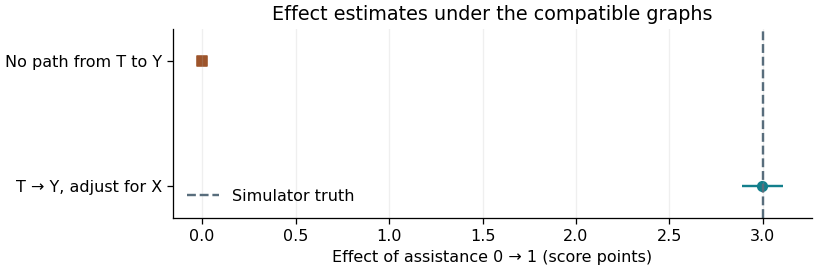

In [9]:
if results:
    fig, ax = plt.subplots(figsize=(7.1, 2.35), layout="constrained")
    if forward_ok:
        label = "T → Y, adjust for X"
        ax.scatter(dose_effect, label, color="#137F8C")
        ax.hlines(label, low, high, color="#137F8C")
    if zero_ok:
        ax.scatter(0, "No path from T to Y", marker="s", color="#9D542B")
    ax.axvline(TRUE_EFFECT, linestyle="--", color="#586D7C", label="Simulator truth")
    ax.set(xlabel="Effect of assistance 0 → 1 (score points)",
           title="Effect estimates under the compatible graphs")
    ax.margins(y=0.25)
    ax.legend(frameon=False)
    ax.grid(axis="x", alpha=.2)
    plt.show()


## B4 · What changes when the evidence changes?

**Time order.** Switch `TIMING` from `"baseline"` to `"ordered"` and rerun. Compare the graph count and effect table. In the starting data, the count goes from **2 to 1** and the forward estimate is **+2.99 points**. The prediction error is **1.62 points** in both runs. Mean absolute error (MAE) is the average absolute difference between a predicted and an observed score on workcells held out from fitting. It answers how accurately we predict recorded scores.

**Shared causes.** Imagine that the shift schedule $U$ influences who receives more assistance and also affects inspection performance. Add $U\to T$ and $U\to Y$ to the original graph. With $h=0.9$, the same simulator has

$$
T=\frac{0.7X+hU+\varepsilon_T}{\sqrt{1.49+h^2}},\qquad
Y=70+3T+1.8X+2hU+2\varepsilon_Y.
$$

$U$ is an independent standard normal draw. $h$ is the strength of the scheduling factor. The two $hU$ terms describe its contributions to assignment and score. In the stress test, the estimate adjusting for $X$ alone is **+4.37**. When the simulator provides $U$ and we adjust for both $X$ and $U$, it is **+2.99**. The known effect in both simulations is **+3.00**. If you set `HIDDEN_STRENGTH = 0.9` in the top settings, B1–B3 show the check from the analyst’s view using only $X,T,Y$.

**中文要点。** 先后顺序解决的是箭头方向的一个问题。排班数据帮助我们判断是否遗漏了同时影响辅助和评分的因素。


In [10]:
train, test = train_test_split(obs, test_size=0.25, random_state=SEED)
forecast = LinearRegression().fit(train[["T", "X"]], train.Y).predict(test[["T", "X"]])
mae = mean_absolute_error(test.Y, forecast)
baseline_mae = mean_absolute_error(test.Y, np.full(len(test), train.Y.median()))
print(f"Held-out prediction MAE: {mae:.2f} points; median baseline: {baseline_mae:.2f}")

stressed = simulate_workcells(0.9)
print("\nScheduling stress test · U now influences assistance and score")
print(f"Adjust for X: {average_gap(stressed):+.2f} points per unit")
print(f"Adjust for X and U: {average_gap(stressed, ('X', 'U')):+.2f} points per unit")
print(f"Known simulated effect: {TRUE_EFFECT:+.2f} points per unit")


Held-out prediction MAE: 1.62 points; median baseline: 3.86

Scheduling stress test · U now influences assistance and score
Adjust for X: +4.37 points per unit
Adjust for X and U: +2.99 points per unit
Known simulated effect: +3.00 points per unit


**Two-minute report.** Show one graph and one numerical result. Say what the timestamp contributes, what comparison uses $X$, and what extra record you would collect, such as which shift or rule assigned the assistance level.

**Read next.** [Pearl’s ACM Turing Award announcement](https://www.acm.org/binaries/content/assets/press-releases/2012/march/turing-award-11.pdf) introduces the research tradition behind causal graphs and interventions. [Kim & Lee (UAI, 2026)](https://proceedings.mlr.press/v337/kim26a.html) ask which independence tests an algorithm can skip. [Guo, Wu & Yiu (UAI, 2026)](https://proceedings.mlr.press/v337/guo26a.html) ask how to make valid inferences after learning a graph. Our small exercise isolates the simpler question of which arrows the recorded data and time order support.


# Share and compare the two approaches

In a **two-minute report**, state the research question, treatment or dose, outcome and units. Show one result and describe the assumption your rerun probes. Explain one piece of evidence you could collect for your own topic.

- **Economists.** Show the group comparison in the historical survey. Use the synthetic panel to show how a differential trend changes the DiD estimate, interval and placebo.
- **Computer scientists.** Show the graph before and after adding timing. Explain how the adjustment estimate and its interval relate to one graph. Name a possible omitted common cause and explain why the prediction metric does not resolve it.

**Individual Ed reply.** *Question and treatment / changed setting / result with units / assumption and check / next evidence for my own study*. If you share a Colab copy, check that the instructor can view it. Keep the survey findings and simulation outputs labeled.

## Source notes

### Economist route

- Card, D., & Krueger, A. B. (1994). *Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania*. American Economic Review, 84(4), 772–793. [Article and Table 3](https://eml.berkeley.edu/~card/papers/njmin-aer.pdf) · [Authors' public data archive](https://davidcard.berkeley.edu/data_sets/njmin.zip).
- Baker, A., Callaway, B., Cunningham, S., Goodman-Bacon, A., & Sant'Anna, P. H. C. (2026). *Difference-in-Differences Designs: A Practitioner's Guide*. Journal of Economic Literature, 64(2), 498–557. [DOI](https://doi.org/10.1257/jel.20251650).
- Wiltshire, J. C., McPherson, C., Reich, M., & Sosinskiy, D. (2026). *Minimum Wage Effects and Monopsony Explanations*. Journal of Labor Economics, 44(4). [DOI](https://doi.org/10.1086/735551).

### Computer scientist route

- Pearl, J. (2009). *Causal inference in statistics: An overview*. Statistics Surveys, 3, 96–146. [DOI](https://doi.org/10.1214/09-SS057).
- Kim, J., & Lee, S. (2026). *Don’t Test What You Can Deduce: Causal Discovery with Logical Inference*. UAI, Proceedings of Machine Learning Research, 337, 2958–2993. [Proceedings](https://proceedings.mlr.press/v337/kim26a.html).
- Guo, D., Wu, J., & Yiu, S. M. (2026). *The Price of Valid Inference After Causal Discovery*. UAI, Proceedings of Machine Learning Research, 337, 1804–1822. [Proceedings](https://proceedings.mlr.press/v337/guo26a.html).